# AP 155 Lab Exercise
---
## Exercise 11: Integration

_Instructions_:
- **Report**: See instructions in Problems
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Luarez, Karl Andrei
- _Student No._: 2024-12430
- _Section_: THR-TX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report figure

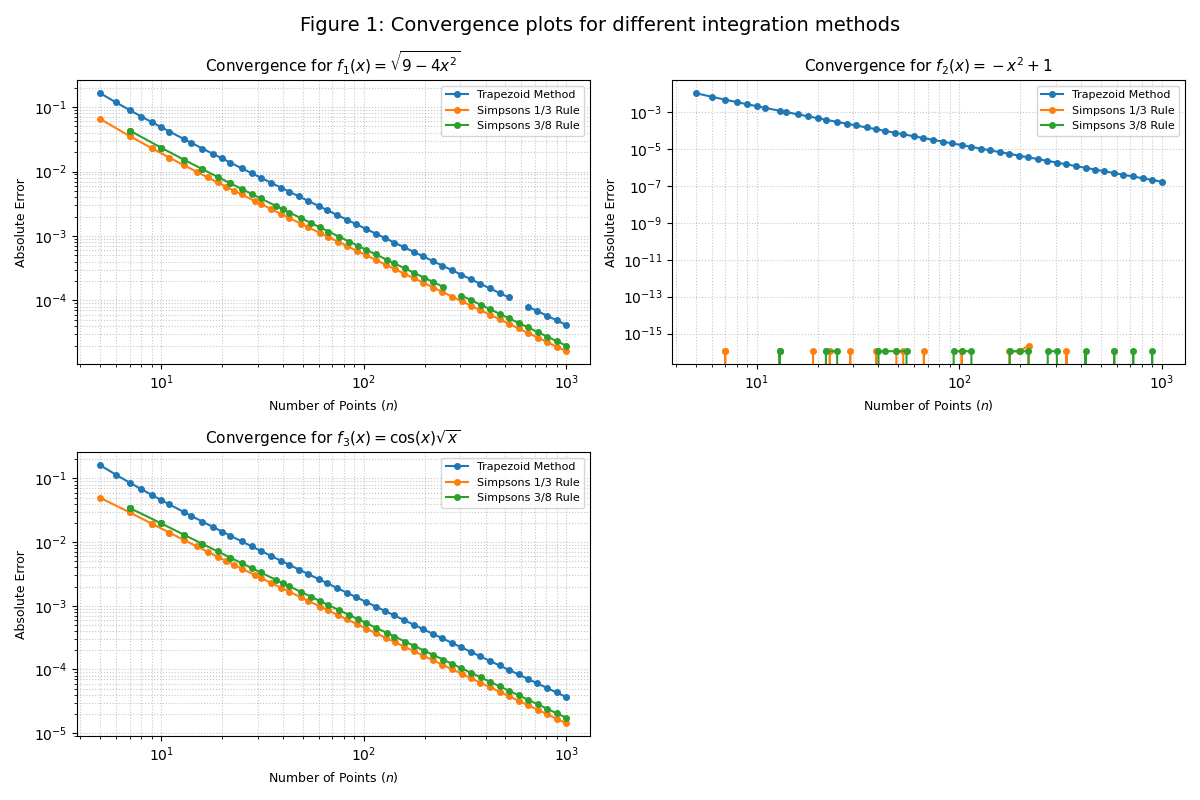
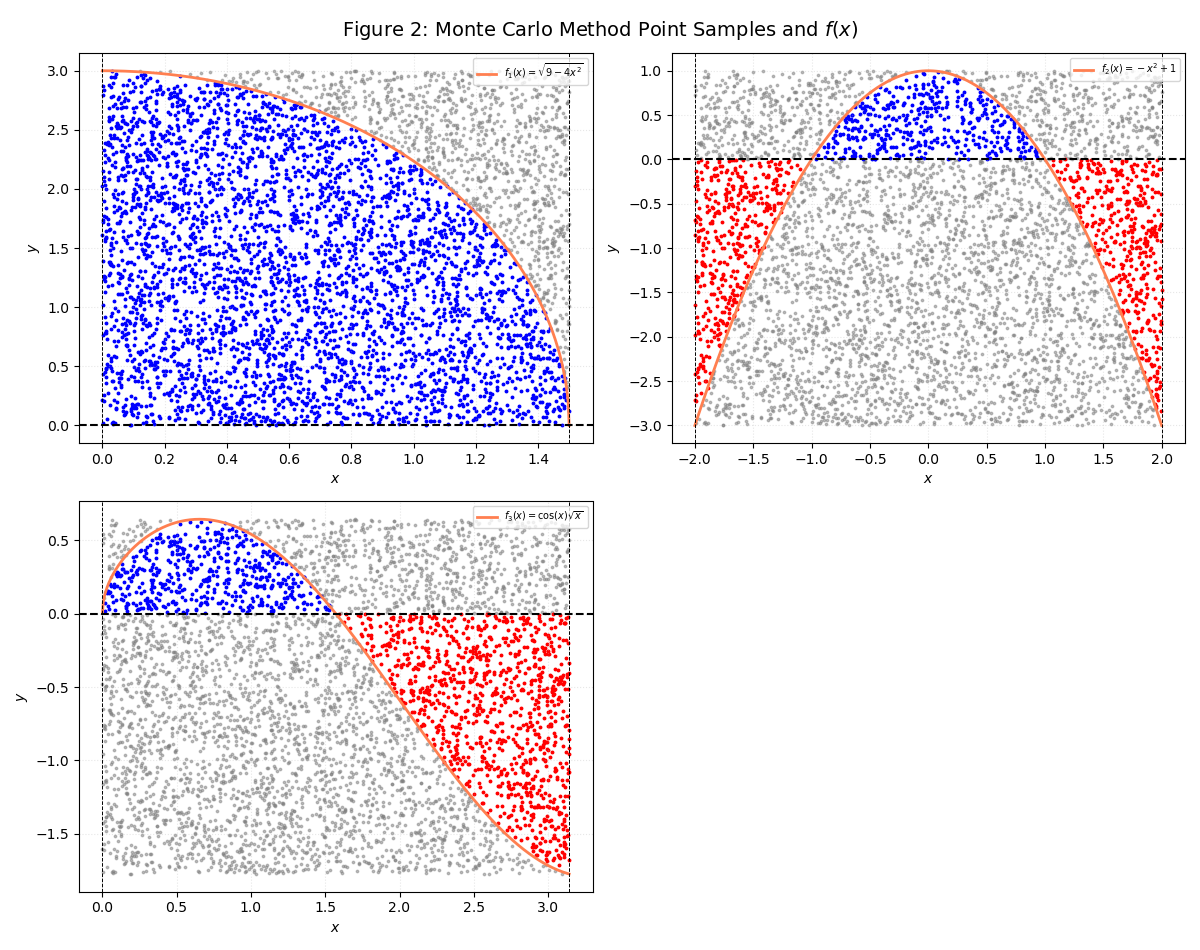


### Report discussion

1. Fig 1 plots the absolute error vs sample points $n$ on a log-log scale. It shows that both Simpson's 1/3 and 3/8 rules converges faster than the Trapezoidal method. For a quadratic function such as $f_2(x)$, the Simpson's methods absolute error drops immediately around $~10^{-15}$. Fig 2 on the other hand visualizes the Monte Carlo method by placing random points in a bounded domain and classifying them into a positive (blue) and negative (red) area contribution or unincluded samples (grey).
2. The Monte Carlo method works for integration by using random sampling over the interval $[a,b]$ then estimating the total area by multiplying the mean function height by the interval size $(b-a)$. By introducing the function $g(x) = c0 + c1*x$, the method samples more in regions in f with higher magnitude and evaluates $f/g$ which compensates for the oversampled points thus reducing variance. The Newtoncotes methods are much more efficient for smooth and continuous functions in lower dimensions (e.g. 3D) since it converges faster while Monte Carlo integration is more convenient for problems with higher dimensions

### Other comments
- No comments


---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
from scipy.integrate import quad

## Problem: 

Given Input:
1. function to integrate
2. bounds
3. number of division/points (for Monte Carlo) 

Make:
1.  a function that can perform Monte Carlo integration
2.  a function that can perform trapezoidal integration
3.  a function that can perform integration via Simpson's Rule (1/3 rule)
4.  a function that can perform integration via Simpson's Rule (3/8 rule)


Output: 
1. total area bounded by the curve, x-axis, and x bounds 
2. signed area (integral)

Make the functions accommodate to any smooth, continuous integrand

Test your functions on the following curves and bounds:

1. $$ y = \sqrt{9-4x^2}, x=0, x=3/2 $$
2. $$ y = -x^2 + 1, x=-2, x=2 $$
3. $$ y = \sqrt{x}\cos{x}, x=0, x=\pi $$

Check your answers (of the integral) with `scipy.integrate.quad`

**Report Figures** (since there are three functions, there should be a total of 6 figures): 
For each function, plot the following: 

1. Plot the absolute error (relative to the integral computed by scipy) vs the number of divisions/intervals, for each method of integration used. In other words, replicate Figure 7.4 of Gezerlis

2. In the Monte Carlo Simulation, plot the points that are bounded by the curve, the x-axis and the other x- bounds. If the point is above the x-axis, paint it blue, if the point is below the x-axis paint it red. If the area is purely above the x-axis, then all the points should be painted blue.

**Report discussion**: 
- Explain the figures.
- Why can we arrive at an integration value using Monte Carlo simulation? When are the Newton-Cotes methods more appropriate/suitable than Monte Carlo methods?



In [2]:
N = 1000
# function endpoints (f1:x1, f2:x2, ...)
x1 = np.linspace(0, 3/2, N) 
x2 = np.linspace(-2, 2, N)
x3 = np.linspace(0, np.pi, N)

f1 = lambda x: np.sqrt(9 - 4*x**2)
f2 = lambda x: -x**2 + 1
f3 = lambda x: np.cos(x)*(np.sqrt(x))

#functions dictionary 
functions= { f1: {"label": r"$f_1(x) = \sqrt{9-4x^2}$", "a": 0, "b": 1.5},
             f2: {"label": r"$f_2(x) = -x^2 + 1$", "a": -2, "b": 2},
             f3: {"label": r"$f_3(x) = \cos(x)\sqrt{x}$", "a": 0, "b": np.pi}}

In [3]:
# Trapezoid

def trapezoid(f, a, b, n):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    cs = np.ones(n); cs[0] = 0.5; cs[-1]=0.5
    contribs = cs*f(xs)
   
    signed_area_trap = h*np.sum(contribs)
    total_area_trap = h*np.sum(np.abs(contribs))

    return signed_area_trap, total_area_trap

print(trapezoid(f1, 0, 3/2, 51))

(3.530552074985812, 3.530552074985812)


In [4]:
# Simpson 1/3

def simpson_13(f, a, b, n):
    if n%2 == 0: #constraint: odd n
        n += 1
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    cs = 2*np.ones(n)
    cs[1::2] = 4; cs[0] = 1; cs[-1] = 1 # 1,4,2,4,2,...,2,4,1
    contribs = cs*f(xs)
    
    signed_area_13 = (h/3)*np.sum(contribs)
    total_area_13 = (h/3)*np.sum(np.abs(contribs))

    return signed_area_13, total_area_13

print(simpson_13(f1, 0, 3/2, 51))

(3.5328291500591256, 3.5328291500591256)


In [5]:
# Simpson 3/8
def simpson_38(f, a, b, n):
    if (n-1)%3 != 0:
        n = n + (3-(n-1) % 3) #constraint: needs 3n+1 points)
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    cs = 3*np.ones(n)
    cs[0::3] = 2; cs[0] = 1; cs[-1] = 1 # 1,3,3,2,3,3,...,2,3,3,1
    contribs = cs*f(xs)
    
    signed_area_38 = (h*(3/8))*np.sum(contribs)
    total_area_38 = (h*(3/8))*np.sum(np.abs(contribs))

    return signed_area_38, total_area_38
print(simpson_38(f1, 0, 3/2, 51))

(3.532562792008511, 3.532562792008511)


/tmp/ipykernel_147657/3176610055.py:7: RuntimeWarning: invalid value encountered in sqrt
  f1 = lambda x: np.sqrt(9 - 4*x**2)


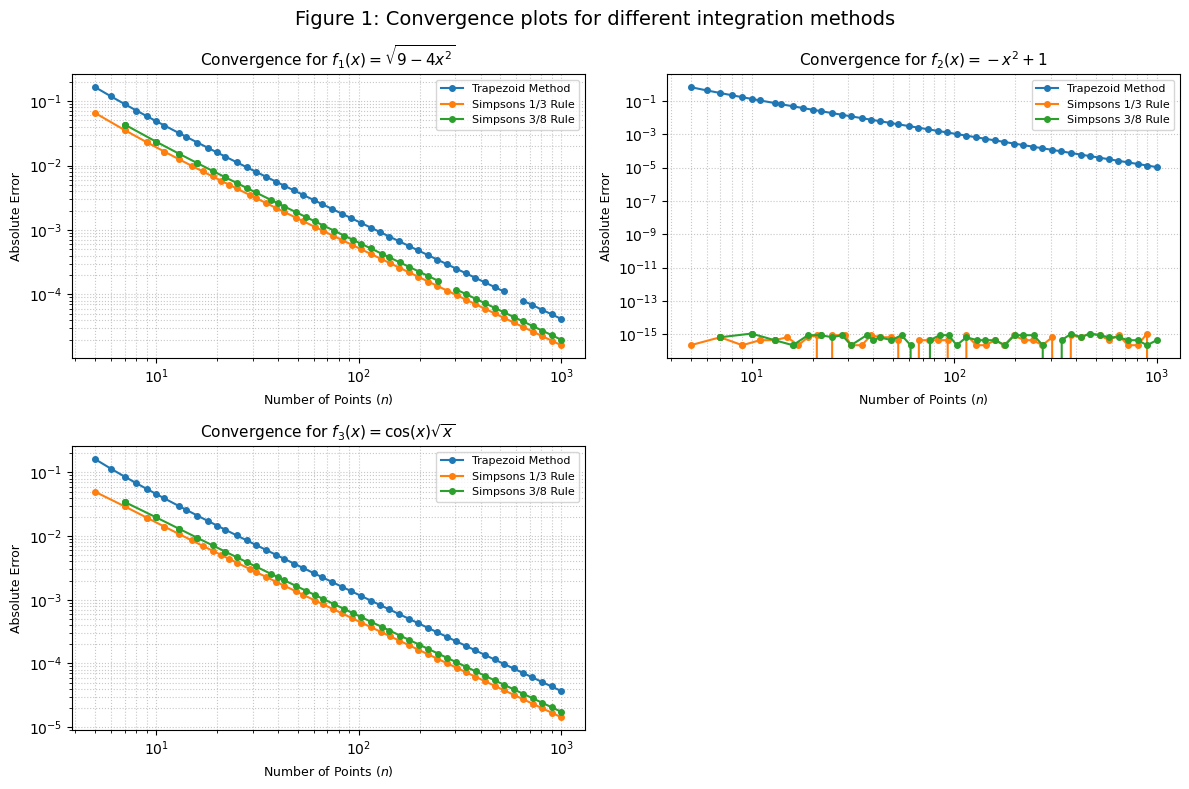

In [6]:
# Error plot

def plot_error(ax, f, info):
    a, b, label = info["a"], info["b"], info["label"]
    methods = {'Trapezoid Method': trapezoid, 'Simpsons 1/3 Rule': simpson_13, 'Simpsons 3/8 Rule': simpson_38}
    
    analytic_signed, _ = quad(f, a, b)
    n_values = np.unique(np.geomspace(5, 1000, 50, dtype=int)) #generating different log grid sizes and ensuring all values are integers

    for method_name, method_func in methods.items():
        errors = []
        plot_n = []
        for n in n_values:
            actual_n = n
            # simpson's rule constraints on n
            if method_name == 'Simpsons 1/3 Rule' and actual_n % 2 == 0:
                actual_n += 1
            elif method_name == 'Simpsons 3/8 Rule' and (actual_n - 1) % 3 != 0:
                actual_n = actual_n + (3 - (actual_n - 1) % 3)
            
            # use actual_n instead of n
            comp_signed, _ = method_func(f, a, b, actual_n)
            error = abs(comp_signed - analytic_signed)
            errors.append(error)
            plot_n.append(actual_n)
            
        ax.loglog(plot_n, errors, 'o-', label=method_name, markersize=4)

    #
    ax.set_xlabel('Number of Points ($n$)', fontsize=9)
    ax.set_ylabel('Absolute Error', fontsize=9)
    ax.set_title(f'Convergence for {label}', fontsize=11)
    ax.grid(which='both', linestyle=":", alpha=0.7)
    ax.legend(fontsize=8)


fig, axes = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle('Figure 1: Convergence plots for different integration methods', fontsize=14)

# Plot each function in dictionary onto its ax
for ax, (func, info) in zip(axes.flat, functions.items()):
    plot_error(ax, func, info)

# Remove 4th subplot
fig.delaxes(axes[1, 1])

plt.tight_layout()
plt.savefig("Figures/Exercise 11 Figure 1.png")
plt.show()

In [7]:
# Monte Carlo

def montecarlo(f, a, b, n, option = "uniform"):
  np.random.seed(42067)
  us = np.random.uniform(a, b, n)
  if option == "uniform":
    fs = f(us)
  else:
    c0 = 4 - np.sqrt(2)
    c1 = -6 + 4*np.sqrt(2)
    xs = (-c0 + np.sqrt(2*c1*us + c0**2))/c1
    fs = f(xs)/(c0+c1*xs)

  fbar, err = stats(fs)
  return (b-a)*fbar, (b-a)*err

def stats(fs):
  n = fs.size
  fbar = np.sum(fs)/n
  fsq = np.sum(fs**2)/n
  varfbar = (fsq-fbar**2)/(n-1)
  return fbar, np.sqrt(varfbar)

for n in 10**np.arange(2,7):
  avu, erru = montecarlo(f1, 0, 3/2, n)
  avi, erri = montecarlo(f1, 0, 3/2, n, option="is")
  rowf = "{0:7d} {1:1.9f} {2:1.9f} {3:1.9f} {4:1.9f}"
  print(rowf.format(n, avu, erru, avi, erri))

    100 3.564192213 0.093208470 1.763505952 0.001178792
   1000 3.534272517 0.032345198 1.762427050 0.000388106
  10000 3.532944403 0.010202552 1.762378259 0.000120351
 100000 3.532315347 0.003181662 1.762644693 0.000037759
1000000 3.535093485 0.001004384 1.762671936 0.000011938


$f_1(x) = \sqrt{9-4x^2}$
    Signed Area: 3.533402099216734
    Error: 0.014432371386134946
    Analytic Integral: 3.534291735288518
$f_2(x) = -x^2 + 1$
    Signed Area: -1.5035130772666798
    Error: 0.06788394164520065
    Analytic Integral: -1.3333333333333335
$f_3(x) = \cos(x)\sqrt{x}$
    Signed Area: -0.879174382843398
    Error: 0.037779213285019014
    Analytic Integral: -0.8948314694841447


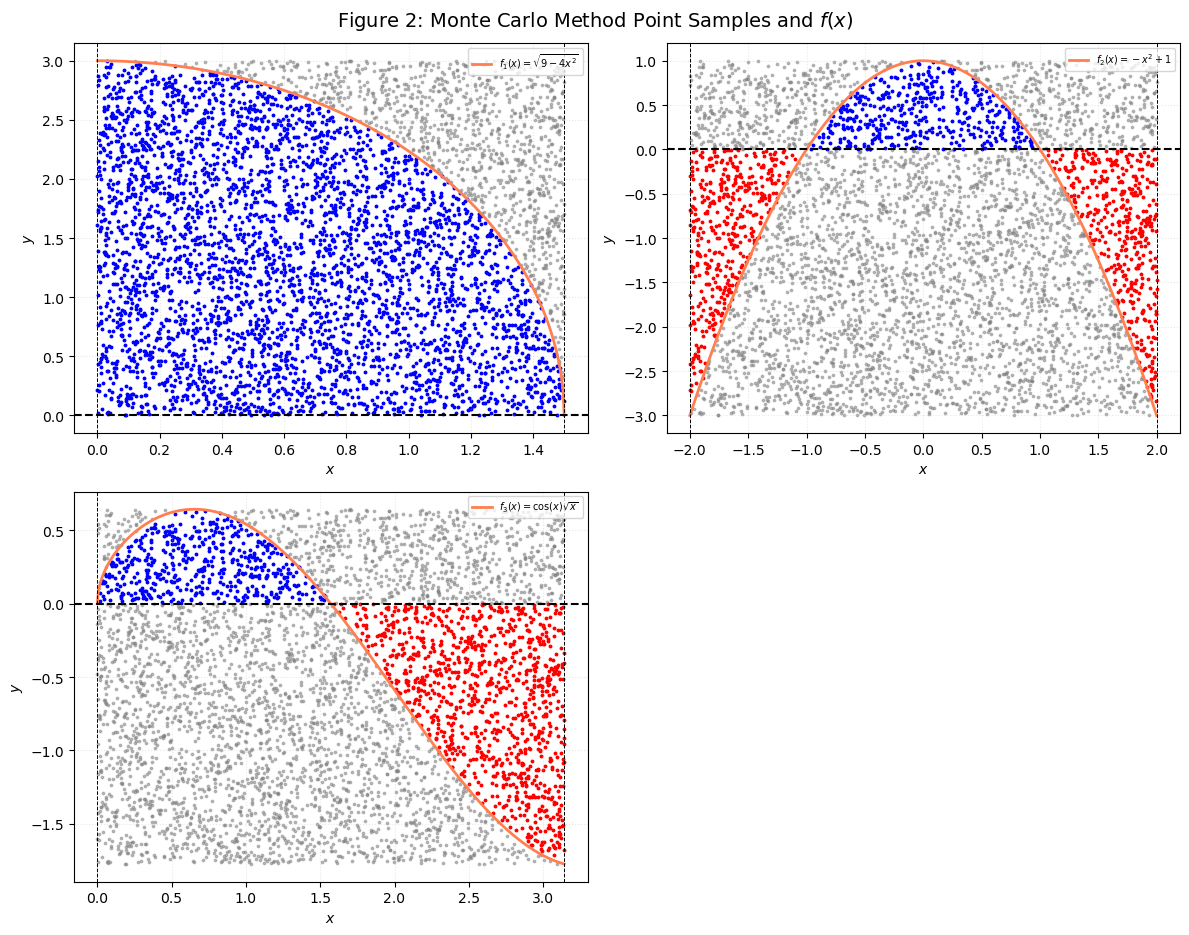

In [10]:
#Plotting monte carlo method

def plot_montecarlo(ax, f, a, b, n, name="Function"):
    # analytic and calculated integral
    signed_area, error = montecarlo(f, a, b, n, option="uniform")
    analytic_int, _ = quad(f, a, b)

    x_m = np.linspace(a, b, 500)
    y_m = f(x_m)
    ymax = max(0, np.max(y_m))
    ymin = min(0, np.min(y_m))

    # Generating random points
    xs = np.random.uniform(a, b, n)
    ys = np.random.uniform(ymin, ymax, n)

    # Defining Regions and colors
    above = (ys > 0) & (ys <= f(xs))  # Above x-axis (blue)
    below = (ys < 0) & (ys >= f(xs))  # Below x-axis (red)
    outside = ~(above | below)        # Not bounded above or below
    ax.scatter(xs[outside], ys[outside], s = 3, color='gray', alpha = 0.5)
    if np.any(above):
        ax.scatter(xs[above], ys[above], s = 3.2, color='blue')
    if np.any(below):
        ax.scatter(xs[below], ys[below], s = 3.2, color='red')

    #Plotting
    ax.plot(x_m, y_m, color='coral', linewidth=2, label=f'{name}')
    ax.axhline(0, color='black', linestyle='--', lw=1.5)
    ax.axvline(a, color='black', linestyle='--', lw=0.7)
    ax.axvline(b, color='black', linestyle='--', lw=0.7)

    ax.set_xlabel('$x$')
    ax.set_ylabel('$y$')
    ax.grid(linestyle=':', alpha=0.3)
    ax.legend(loc = 'upper right', fontsize=7)

    print(f"{name}")
    print(f"    Signed Area: {signed_area}")
    print(f"    Error: {error}")
    print(f"    Analytic Integral: {analytic_int}")

fig, axes = plt.subplots(2, 2, figsize=(12, 9.5),)
fig.suptitle(r'Figure 2: Monte Carlo Method Point Samples and $f(x)$', fontsize = 14)

for ax, (f, info) in zip(axes.flat, functions.items()):
    name = info["label"]
    a = info["a"]
    b = info["b"]
    plot_montecarlo(ax, f, a, b, 5000, name=name)

# Remove unused 4th subplot
fig.delaxes(axes[1, 1])

plt.tight_layout()
plt.savefig("Figures/Exercise 11 Figure 2.png")
plt.show()
